<a href="https://colab.research.google.com/github/maximofernandezriera/taller-pizarra/blob/main/repaso-IFC33A-TALLER-B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Repaso del examen: IFC33A-TALLER-B1 — el taller de Marina

Marina regenta el taller de bicicletas del barrio. Cada mañana recibe bicis para reparar, controla el stock de piezas en la trastienda, apunta las tarifas y revisa las bicis estáticas de la sala de pruebas. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas.

Este cuaderno repasa los 13 ejercicios del examen nuevo: seis preguntas de test, cuatro seguimientos de código y tres funciones. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno.

# Repaso del examen: IFC33A-TALLER-B1 — el taller de Marina

Marina regenta el taller de bicicletas del barrio. Cada mañana recibe bicis para reparar, controla el stock de piezas en la trastienda, apunta las tarifas y revisa las bicis estáticas de la sala de pruebas. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas.

Este cuaderno repasa los 13 ejercicios del examen nuevo: seis preguntas de test, cuatro seguimientos de código y tres funciones. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno.

> **[Abrir este cuaderno en Google Colab](https://colab.research.google.com/github/maximofernandezriera/taller-pizarra/blob/main/repaso-IFC33A-TALLER-B1.ipynb)**# Repaso del examen: IFC33A-TALLER-B1 — el taller de Marina

Marina regenta el taller de bicicletas del barrio. Cada mañana recibe bicis para reparar, controla el stock de piezas en la trastienda, apunta las tarifas y revisa las bicis estáticas de la sala de pruebas. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas.

Este cuaderno repasa los 13 ejercicios del examen nuevo: seis preguntas de test, cuatro seguimientos de código y tres funciones. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno.

> **[Abrir este cuaderno en Google Colab](https://colab.research.google.com/drive/1YLhypdQ5eb16CT-Hnbn3RgjpndZ2H0EW)** — archivo privado en el Drive del profesor; el enlace está verificado. No compartir fuera del grupo.

## Cómo se ha corregido

- El examen suma **30 puntos**: parte A, 6; parte B, 12; parte C, 12.
- En la parte A hay **1 punto por acierto**, con una sola opción correcta por pregunta.
- En cada seguimiento de la parte B, 2 puntos corresponden a la tabla de variables y 1 punto a la salida exacta.
- En la parte C se puntúa por criterios y se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

En el test, **cada acierto suma 1 punto** y cada fallo o respuesta en blanco suma **0**: no se resta nada adicional. Se aprueba con **15 de los 30 puntos** (equivalente a 5/10), **sin mínimos por parte**, y la nota sobre 10 es el **total dividido entre 3**; el total se calcula sin redondeo previo y solo se redondea al mostrarlo, de modo que una nota por debajo de 15 no llega a aprobado por redondeo.

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra, las listas, los avances y las tablas que usaremos durante el repaso.

In [ ]:
#@title Caja de herramientas visual
import doctest
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    display(fig)
    plt.close(fig)

def dibujar_estante(estante, marcar=(), titulo=""):
    """Dibuja las casillas de un estante con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(estante)), 2.6), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(-0.1, 1.45, titulo, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono",
            va="center")
    for i, letra in enumerate(estante):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, letra, ha="center", va="center",
                fontsize=20, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(estante)) + 0.15)
    ax.set_ylim(-0.55, 1.9)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_lista(elementos, marcar=(), titulo=""):
    """Dibuja una casilla por elemento de lista, con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(elementos)), 2.6), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(-0.1, 1.45, titulo, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono",
            va="center")
    for i, elemento in enumerate(elementos):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, str(elemento), ha="center", va="center",
                fontsize=17, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(elementos)) + 0.15)
    ax.set_ylim(-0.55, 1.9)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_listas_doble(antes, despues, titulo, nota=""):
    """Compara la lista original y la lista nueva en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, elementos) in enumerate(
            (("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, elemento in enumerate(elementos):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, str(elemento),
                    transform=ax.transAxes, ha="center", va="center",
                    fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    if nota:
        ax.text(0.5, 0.02, nota, transform=ax.transAxes, ha="center",
                color=TIZA_AMARILLA, fontsize=12,
                family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

def dibujar_avances(posiciones, marca, titulo, nota=""):
    """Dibuja los saltos de un contador sobre una recta, con su marca."""
    fig, ax = plt.subplots(figsize=(9, 3.0), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ultima = max(max(posiciones), marca)
    ax.set_xlim(-0.9, ultima + 0.9)
    ax.set_ylim(-1.05, 2.2)
    ax.axis("off")
    ax.text(0.5, 0.98, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    ax.plot([-0.6, ultima + 0.6], [0, 0], color=TIZA, linewidth=2)
    for casilla in range(ultima + 1):
        visitada = casilla in posiciones
        ax.add_patch(Rectangle((casilla - 0.34, -0.28), 0.68, 0.56,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if visitada else TIZA,
                               linewidth=2 if visitada else 1))
        ax.text(casilla, -0.58, str(casilla), ha="center", va="top",
                color=TIZA, fontsize=11, family="DejaVu Sans Mono")
    for paso, (origen, destino) in enumerate(
            zip(posiciones, posiciones[1:]), 1):
        altura = 0.56 + 0.24 * (paso - 1)
        ax.annotate("", xy=(destino, altura), xytext=(origen, altura),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text((origen + destino) / 2, altura + 0.10,
                f"+{destino - origen}", ha="center", color=TIZA, fontsize=10,
                family="DejaVu Sans Mono")
    ax.plot([marca, marca], [-0.34, 1.50], color=TIZA_AZUL, linewidth=2,
            linestyle="--")
    ax.text(marca, 1.58, f"marca {marca}", ha="center", color=TIZA_AZUL,
            fontsize=11, family="DejaVu Sans Mono")
    ax.plot(posiciones[-1], 0, marker="s", markersize=11,
            color=TIZA_AMARILLA, markeredgecolor=TIZA)
    if nota:
        ax.text(0.5, 0.02, nota, transform=ax.transAxes, ha="center",
                color=TIZA_AMARILLA, fontsize=12,
                family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

def dibujar_tabla_pizarra(titulo, columnas, filas, pesos=None):
    """Dibuja una tabla de seguimiento legible en la pizarra."""
    fig, ax = plt.subplots(figsize=(10, max(2.8, 0.48 * (len(filas) + 2))), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.5, 0.96, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    izquierda, derecha = 0.05, 0.95
    arriba, abajo = 0.82, 0.08
    if pesos is None:
        pesos = [1] * len(columnas)
    total = sum(pesos)
    anchos = [p / total * (derecha - izquierda) for p in pesos]
    bordes = [izquierda + sum(anchos[:c]) for c in range(len(columnas) + 1)]
    alto = (arriba - abajo) / (len(filas) + 1)
    for r in range(len(filas) + 2):
        y = arriba - r * alto
        ax.plot([izquierda, derecha], [y, y], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    for c in range(len(columnas) + 1):
        x = bordes[c]
        ax.plot([x, x], [abajo, arriba], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    tabla = [columnas] + filas
    for r, fila in enumerate(tabla):
        for c, valor in enumerate(fila):
            x = bordes[c] + anchos[c] / 2
            y = arriba - (r + 0.5) * alto
            ax.text(x, y, str(valor), transform=ax.transAxes, ha="center",
                    va="center", color=TIZA_AMARILLA if r == 0 else TIZA,
                    fontsize=12, family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

print("Caja lista: pizarra, listas, avances y tablas.")


Caja lista: pizarra, listas, avances y tablas.


## A1 · El lote de bicis por limpiar (1 punto)

### Enunciado exacto

Marina limpia una tanda de 6 bicis de una en una y deja de limpiar cuando le quedan 3 o menos pendientes. ¿Qué imprime este código?

```python
bicis = 6
while bicis > 3:
    bicis = bicis - 1
print(bicis)
```

a) 6    b) 4    c) 3    d) El bucle no termina

### Pizarra

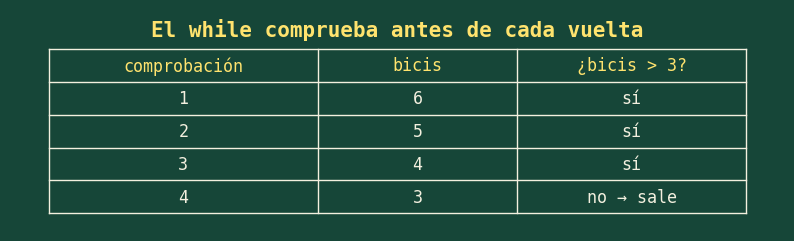

In [ ]:
dibujar_tabla_pizarra(
    'El while comprueba antes de cada vuelta',
    ['comprobación', 'bicis', '¿bicis > 3?'],
    [['1', '6', 'sí'], ['2', '5', 'sí'], ['3', '4', 'sí'], ['4', '3', 'no → sale']],
    pesos=[1.35, 1, 1.15],
)

In [ ]:
bicis = 6
while bicis > 3:
    bicis = bicis - 1
print(bicis)

3


**Paso a paso.** El `while` comprueba `bicis > 3` antes de cada vuelta. La variable pasa de 6 a 5, de 5 a 4 y de 4 a 3; cuando vale 3 la condición ya no se cumple y el bucle termina. La respuesta es **c) 3**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=bicis%20%3D%206%0Awhile%20bicis%20%3E%203%3A%0A%20%20%20%20bicis%20%3D%20bicis%20-%201%0Aprint%28bicis%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: c) 3 — 1 p por acierto. | 1 |

#### Errores frecuentes

- Responder 6: ignora que `bicis` se actualiza dentro del bucle (opción a).
- Detener el bucle una vuelta antes y contestar 4 (opción b).
- Creer que el bucle no termina: `bicis` disminuye en cada vuelta (opción d).

## A2 · Reparaciones por clienta (1 punto)

### Enunciado exacto

Marina lleva en un diccionario cuántas bicis tiene en reparación cada clienta. Irene trae una bici más y Noa llega por primera vez con 1. ¿Qué imprime este código?

```python
arreglos = {"Irene": 2, "Pau": 4}
arreglos["Irene"] = arreglos["Irene"] + 1
arreglos["Noa"] = 1
print(arreglos["Irene"], len(arreglos))
```

a) 2 2    b) 3 2    c) 3 3    d) 2 3

### Pizarra

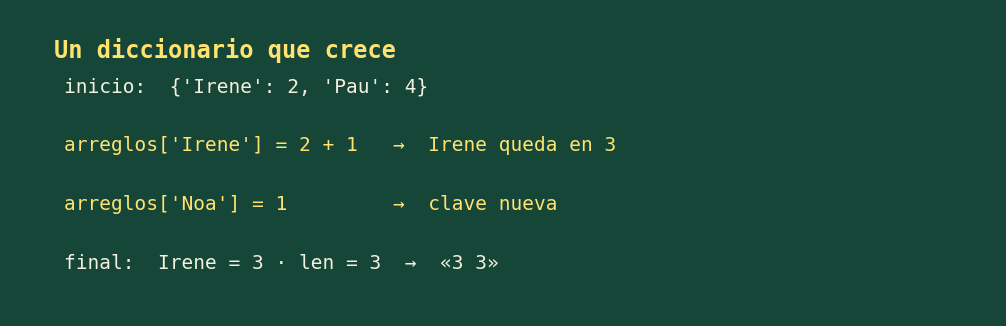

In [ ]:
dibujar_pizarra(
    'Un diccionario que crece',
    [("inicio:  {'Irene': 2, 'Pau': 4}", TIZA), ("arreglos['Irene'] = 2 + 1   →  Irene queda en 3", TIZA_AMARILLA), ("arreglos['Noa'] = 1         →  clave nueva", TIZA_AMARILLA), ('final:  Irene = 3 · len = 3  →  «3 3»', TIZA)],
    ancho=10, alto=3.2,
)

In [ ]:
arreglos = {"Irene": 2, "Pau": 4}
arreglos["Irene"] = arreglos["Irene"] + 1
arreglos["Noa"] = 1
print(arreglos["Irene"], len(arreglos))

3 3


**Paso a paso.** `arreglos["Irene"]` pasa de 2 a 3 con la suma, y `arreglos["Noa"] = 1` añade una clave nueva: el diccionario queda con tres clientes. Se imprime el valor de Irene, 3, y la longitud, 3. La respuesta es **c) 3 3**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=arreglos%20%3D%20%7B%22Irene%22%3A%202%2C%20%22Pau%22%3A%204%7D%0Aarreglos%5B%22Irene%22%5D%20%3D%20arreglos%5B%22Irene%22%5D%20%2B%201%0Aarreglos%5B%22Noa%22%5D%20%3D%201%0Aprint%28arreglos%5B%22Irene%22%5D%2C%20len%28arreglos%29%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: c) 3 3 — 1 p por acierto. | 1 |

#### Errores frecuentes

- Olvidar que `arreglos["Irene"]` se actualiza antes de imprimir (opciones a y d).
- No contar `Noa` como clave nueva al calcular `len` (opciones a y b).

## A3 · Códigos del expositor de piezas (1 punto)

### Enunciado exacto

Marina actualiza la lista de códigos de las piezas del expositor: retira el 25, que se ha agotado, y añade el 55, que acaba de llegar. ¿Qué imprime este código?

```python
piezas = [15, 25, 35, 45]
piezas.remove(25)
piezas.append(55)
print(piezas[2], len(piezas))
```

a) 35 4    b) 45 4    c) 45 3    d) 25 4

### Pizarra

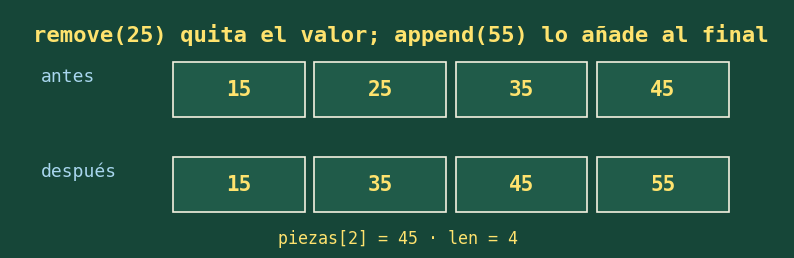

In [ ]:
dibujar_listas_doble([15, 25, 35, 45], [15, 35, 45, 55], 'remove(25) quita el valor; append(55) lo añade al final', nota='piezas[2] = 45 · len = 4')

In [ ]:
piezas = [15, 25, 35, 45]
piezas.remove(25)
piezas.append(55)
print(piezas[2], len(piezas))

45 4


**Paso a paso.** `remove(25)` quita el valor 25, no la casilla 2: la lista queda `[15, 35, 45]`. Después `append(55)` la deja en `[15, 35, 45, 55]`. En la posición 2 está el 45 y la longitud es 4. La respuesta es **b) 45 4**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=piezas%20%3D%20%5B15%2C%2025%2C%2035%2C%2045%5D%0Apiezas.remove%2825%29%0Apiezas.append%2855%29%0Aprint%28piezas%5B2%5D%2C%20len%28piezas%29%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: b) 45 4 — 1 p por acierto. | 1 |

#### Errores frecuentes

- Confundir índice y valor: `piezas[2]` es el tercer elemento (opción a).
- Pensar que `append` sustituye un elemento y la lista se queda en 3 (opción c).
- Leer `remove` como borrado por índice o creer que el 25 sigue (opción d).

## A4 · Stock de la trastienda (1 punto)

### Enunciado exacto

En la trastienda, Marina controla las existencias con un diccionario y consulta sillines y frenos. ¿Qué imprime este código?

```python
stock = {"cadena": 4, "frenos": 6}
print(stock.get("sillin"), stock.get("frenos", 0))
```

a) 0 6    b) None 6    c) sillin 6    d) KeyError

### Pizarra

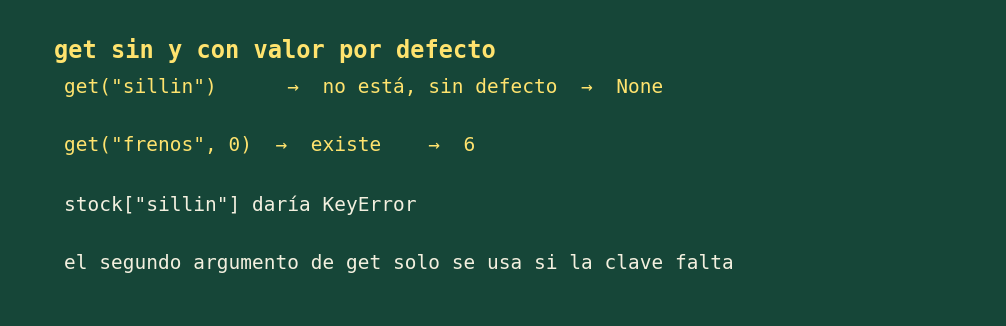

In [ ]:
dibujar_pizarra(
    'get sin y con valor por defecto',
    [('get("sillin")      →  no está, sin defecto  →  None', TIZA_AMARILLA), ('get("frenos", 0)  →  existe    →  6', TIZA_AMARILLA), ('stock["sillin"] daría KeyError', TIZA), ('el segundo argumento de get solo se usa si la clave falta', TIZA)],
    ancho=10, alto=3.2,
)

In [ ]:
stock = {"cadena": 4, "frenos": 6}
print(stock.get("sillin"), stock.get("frenos", 0))

None 6


**Paso a paso.** `get("sillin")` no encuentra la clave y devuelve `None`, porque no se ha pasado valor por defecto. `get("frenos", 0)` sí encuentra la clave y devuelve 6, sin usar el por defecto. Con `stock["sillin"]` habría un `KeyError`. La respuesta es **b) None 6**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=stock%20%3D%20%7B%22cadena%22%3A%204%2C%20%22frenos%22%3A%206%7D%0Aprint%28stock.get%28%22sillin%22%29%2C%20stock.get%28%22frenos%22%2C%200%29%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: b) None 6 — 1 p por acierto. | 1 |

#### Errores frecuentes

- Creer que `get` sin segundo argumento devuelve 0 (opción a).
- Pensar que `get` devuelve la clave en lugar del valor (opción c).
- Confundir `get` con el acceso `stock["sillin"]`, que sí lanzaría `KeyError` (opción d).

## A5 · Tipo de revisión según kilómetros (1 punto)

### Enunciado exacto

Marina clasifica cada revisión por los kilómetros de la bici: «completa» a partir de 9000 km, «media» a partir de 3000 km y «basica» por debajo. Con una bici de 3200 km, ¿Qué imprime este código?

```python
km = 3200
if km >= 9000:
    print("completa")
elif km >= 3000:
    print("media")
else:
    print("basica")
```

a) completa    b) media    c) basica    d) mediabasica

### Pizarra

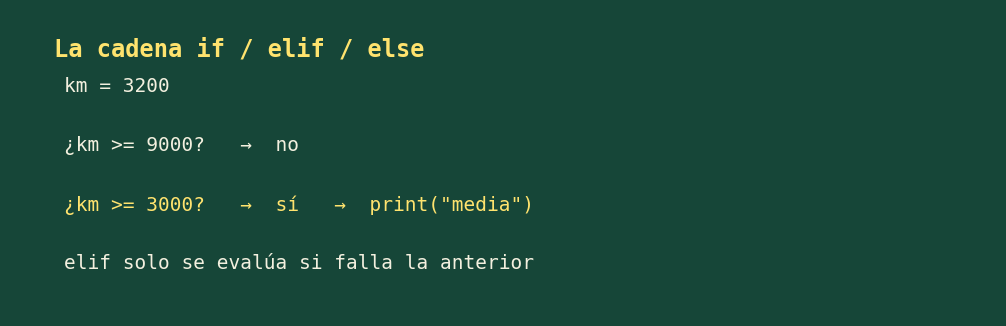

In [ ]:
dibujar_pizarra(
    'La cadena if / elif / else',
    [('km = 3200', TIZA), ('¿km >= 9000?   →  no', TIZA), ('¿km >= 3000?   →  sí   →  print("media")', TIZA_AMARILLA), ('elif solo se evalúa si falla la anterior', TIZA)],
    ancho=10, alto=3.2,
)

In [ ]:
km = 3200
if km >= 9000:
    print("completa")
elif km >= 3000:
    print("media")
else:
    print("basica")

media

**Paso a paso.** Las ramas se evalúan en orden y solo hasta que una se cumple. Como 3200 no llega a 9000, la primera falla; como 3200 sí es `>= 3000`, entra en el `elif` e imprime `media`. El `else` no se mira. La respuesta es **b) media**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=km%20%3D%203200%0Aif%20km%20%3E%3D%209000%3A%0A%20%20%20%20print%28%22completa%22%29%0Aelif%20km%20%3E%3D%203000%3A%0A%20%20%20%20print%28%22media%22%29%0Aelse%3A%0A%20%20%20%20print%28%22basica%22%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: b) media — 1 p por acierto. | 1 |

#### Errores frecuentes

- Evaluar solo la primera rama o creer que 3200 llega a 9000 (opción a).
- Creer que 3200 cae en el `else` por no llegar a 9000 (opción c).
- Pensar que se ejecutan dos ramas y contestar «mediabasica» (opción d).

## A6 · La bici estática de tres en tres (1 punto)

### Enunciado exacto

Marina cuenta los kilómetros de la bici estática de tres en tres y se detiene en cuanto el contador llega a 10 o más. ¿Qué imprime este código?

```python
i = 0
while True:
    i = i + 3
    if i >= 10:
        break
print(i)
```

a) 9    b) 10    c) 12    d) 15

### Pizarra

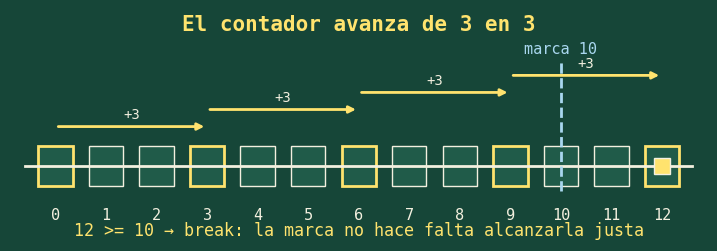

In [ ]:
dibujar_avances([0, 3, 6, 9, 12], 10, 'El contador avanza de 3 en 3', nota='12 >= 10 → break: la marca no hace falta alcanzarla justa')

In [ ]:
i = 0
while True:
    i = i + 3
    if i >= 10:
        break
print(i)

12


**Paso a paso.** `i` sube de tres en tres: 3, 6, 9, 12. Al llegar a 12 la condición `i >= 10` se cumple — con `>=` basta pasarse, no hace falta caer justo en 10 — salta el `break` y se imprime 12. La respuesta es **c) 12**.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=i%20%3D%200%0Awhile%20True%3A%0A%20%20%20%20i%20%3D%20i%20%2B%203%0A%20%20%20%20if%20i%20%3E%3D%2010%3A%0A%20%20%20%20%20%20%20%20break%0Aprint%28i%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Respuesta correcta: c) 12 — 1 p por acierto. | 1 |

#### Errores frecuentes

- Salir una vuelta antes e imprimir 9 (opción a).
- Creer que el bucle para exactamente en 10 (opción b): `i` salta de 3 en 3.
- Dar una vuelta de más e imprimir 15 (opción d).

## B1 · El medidor hasta la marca 11 (3 puntos)

### Enunciado exacto

Marina prueba una bici en el rodillo. En cada vuelta el medidor `avance` sube cuatro kilómetros y `vueltas` cuenta las pasadas. Se detiene en cuanto alcanza o supera la marca 11. Completa la tabla y escribe la salida exacta.

```python
vueltas = 0
avance = 0
while True:
    avance = avance + 4
    vueltas = vueltas + 1
    if avance >= 11:
        break
print("marca:", avance)
print("vueltas:", vueltas)
```

Columnas de la tabla: vuelta | avance | vueltas.

### Pizarra

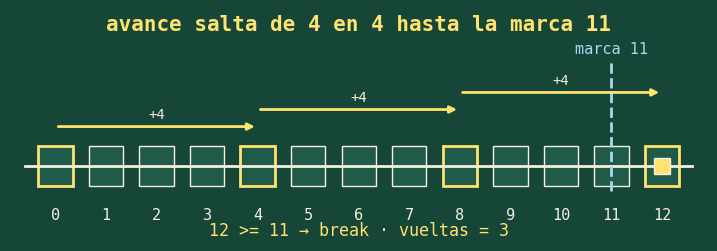

In [ ]:
dibujar_avances([0, 4, 8, 12], 11, 'avance salta de 4 en 4 hasta la marca 11', nota='12 >= 11 → break · vueltas = 3')

In [ ]:
vueltas = 0
avance = 0
while True:
    avance = avance + 4
    vueltas = vueltas + 1
    if avance >= 11:
        break
print("marca:", avance)
print("vueltas:", vueltas)

marca: 12
vueltas: 3


In [ ]:
filas_b1 = [{'vuelta': '1', 'avance': '4', 'vueltas': '1'}, {'vuelta': '2', 'avance': '8', 'vueltas': '2'}, {'vuelta': '3', 'avance': '12', 'vueltas': '3 (break)'}]
traza_pasos(filas_b1, ['vuelta', 'avance', 'vueltas'])

vuelta,avance,vueltas
1,4,1
2,8,2
3,12,3 (break)


**Paso a paso.** En cada vuelta `avance` sube cuatro kilómetros y `vueltas` suma uno. La primera vuelta deja el medidor en 4, la segunda en 8 y la tercera en 12; como 12 ya alcanza la marca 11, el `break` detiene el bucle. Los dos `print` muestran `marca: 12` y `vueltas: 3`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=vueltas%20%3D%200%0Aavance%20%3D%200%0Awhile%20True%3A%0A%20%20%20%20avance%20%3D%20avance%20%2B%204%0A%20%20%20%20vueltas%20%3D%20vueltas%20%2B%201%0A%20%20%20%20if%20avance%20%3E%3D%2011%3A%0A%20%20%20%20%20%20%20%20break%0Aprint%28%22marca%3A%22%2C%20avance%29%0Aprint%28%22vueltas%3A%22%2C%20vueltas%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Tabla de variables: columnas correctas según la lista dada (0,5) · valores al final de cada vuelta correctos, incluida la vuelta del break cuando lo hay (1,0) · sin filas ni columnas inventadas (0,5) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- No anotar la vuelta en la que salta el `break`: la rúbrica la pide también.
- Confundir el medidor (`avance`) con el número de pasadas (`vueltas`).
- Añadir filas después del break, cuando el bucle ya ha terminado.

## B2 · La primera rueda descentrada (3 puntos)

### Enunciado exacto

Marina revisa la lista de mediciones de desgaste de las bicis de hoy y quiere la posición de la primera que supera 9. Completa la tabla y escribe la salida exacta.

```python
lecturas = [6, 8, 11, 5, 9]
indice = 0
hallada = -1
for t in lecturas:
    if t > 9:
        hallada = indice
        break
    indice = indice + 1
print("casilla:", hallada)
```

Columnas de la tabla: vuelta | t | indice | hallada.

*Nota: hallada vale -1 antes de empezar el bucle; anota su valor al final de cada vuelta.*

### Pizarra

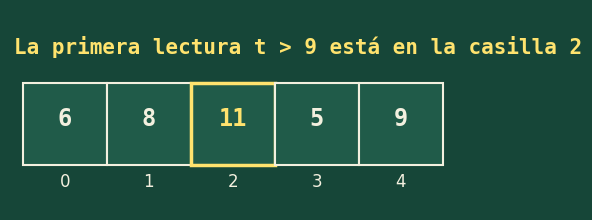

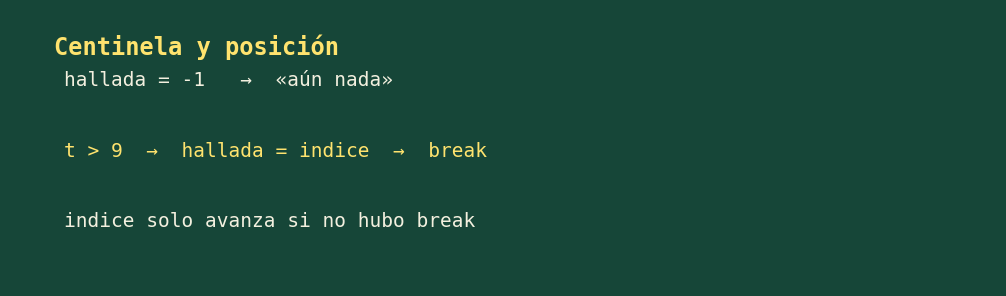

In [ ]:
dibujar_lista([6, 8, 11, 5, 9], marcar=[2], titulo='La primera lectura t > 9 está en la casilla 2')
dibujar_pizarra(
    'Centinela y posición',
    [('hallada = -1   →  «aún nada»', TIZA), ('t > 9  →  hallada = indice  →  break', TIZA_AMARILLA), ('indice solo avanza si no hubo break', TIZA)],
    ancho=10, alto=2.9,
)

In [ ]:
lecturas = [6, 8, 11, 5, 9]
indice = 0
hallada = -1
for t in lecturas:
    if t > 9:
        hallada = indice
        break
    indice = indice + 1
print("casilla:", hallada)

casilla: 2


In [ ]:
filas_b2 = [{'vuelta': '1', 't': '6', 'indice': '1', 'hallada': '-1'}, {'vuelta': '2', 't': '8', 'indice': '2', 'hallada': '-1'}, {'vuelta': '3', 't': '11', 'indice': '2', 'hallada': '2 (break)'}]
traza_pasos(filas_b2, ['vuelta', 't', 'indice', 'hallada'])

vuelta,t,indice,hallada
1,6,1,-1
2,8,2,-1
3,11,2,2 (break)


**Paso a paso.** `hallada` nace en -1 como señal de «aún no hay nada». El bucle mira cada valor de `lecturas`: con 6 y 8 no pasa nada, solo avanza `indice`. Cuando llega el 11 se cumple `t > 9`, se guarda la posición 2 y el `break` corta el recorrido. Se imprime `casilla: 2`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=lecturas%20%3D%20%5B6%2C%208%2C%2011%2C%205%2C%209%5D%0Aindice%20%3D%200%0Ahallada%20%3D%20-1%0Afor%20t%20in%20lecturas%3A%0A%20%20%20%20if%20t%20%3E%209%3A%0A%20%20%20%20%20%20%20%20hallada%20%3D%20indice%0A%20%20%20%20%20%20%20%20break%0A%20%20%20%20indice%20%3D%20indice%20%2B%201%0Aprint%28%22casilla%3A%22%2C%20hallada%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Tabla de variables: columnas correctas según la lista dada (0,5) · valores al final de cada vuelta correctos, incluida la vuelta del break cuando lo hay (1,0) · sin filas ni columnas inventadas (0,5) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Olvidar que `hallada` empieza en -1 antes del bucle.
- Anotar el valor de `t` en la columna `hallada` en lugar de la posición.
- Sumar uno a `indice` también en la vuelta del break.

## B3 · Cifras y letras del número de serie (3 puntos)

### Enunciado exacto

Marina copia el número de serie «b4c9a» de un cuadro y separa las cifras, que apunta para el pedido, de las letras. Completa la tabla y escribe la salida exacta.

```python
serie = "b4c9a"
cifras = []
resto = 0
for c in serie:
    if c in "0123456789":
        cifras.append(c)
    else:
        resto = resto + 1
print(cifras)
print("resto:", resto)
```

Columnas de la tabla: vuelta | c | cifras | resto.

### Pizarra

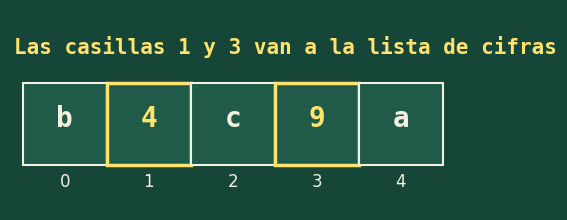

In [ ]:
dibujar_estante('b4c9a', marcar=[1, 3], titulo='Las casillas 1 y 3 van a la lista de cifras')

In [ ]:
serie = "b4c9a"
cifras = []
resto = 0
for c in serie:
    if c in "0123456789":
        cifras.append(c)
    else:
        resto = resto + 1
print(cifras)
print("resto:", resto)

['4', '9']
resto: 3


In [ ]:
filas_b3 = [{'vuelta': '1', 'c': 'b', 'cifras': '[]', 'resto': '1'}, {'vuelta': '2', 'c': '4', 'cifras': "['4']", 'resto': '1'}, {'vuelta': '3', 'c': 'c', 'cifras': "['4']", 'resto': '2'}, {'vuelta': '4', 'c': '9', 'cifras': "['4', '9']", 'resto': '2'}, {'vuelta': '5', 'c': 'a', 'cifras': "['4', '9']", 'resto': '3'}]
traza_pasos(filas_b3, ['vuelta', 'c', 'cifras', 'resto'])

vuelta,c,cifras,resto
1,b,[],1
2,4,['4'],1
3,c,['4'],2
4,9,"['4', '9']",2
5,a,"['4', '9']",3


**Paso a paso.** El `for` recorre el número de serie carácter a carácter. Las cifras `4` y `9` entran en la lista `cifras` como cadenas, con sus comillas; el resto de caracteres suma uno a `resto`. Al terminar se imprime `['4', '9']` y `resto: 3`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=serie%20%3D%20%22b4c9a%22%0Acifras%20%3D%20%5B%5D%0Aresto%20%3D%200%0Afor%20c%20in%20serie%3A%0A%20%20%20%20if%20c%20in%20%220123456789%22%3A%0A%20%20%20%20%20%20%20%20cifras.append%28c%29%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20resto%20%3D%20resto%20%2B%201%0Aprint%28cifras%29%0Aprint%28%22resto%3A%22%2C%20resto%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Tabla de variables: columnas correctas según la lista dada (0,5) · valores al final de cada vuelta correctos, incluida la vuelta del break cuando lo hay (1,0) · sin filas ni columnas inventadas (0,5) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Guardar el entero 4 en lugar de la cadena `'4'`: la salida sería `[4, 9]`, sin comillas.
- Contar las cifras también en `resto`.
- Escribir la salida sin corchetes o sin comillas.

## B4 · El ticket de la mañana (3 puntos)

### Enunciado exacto

Marina apunta el ticket de una reparación: suma el total de lo que está en la tarifa y cuenta aparte lo que no está. Completa la tabla y escribe la salida exacta.

```python
tarifa = {"camara": 8, "pastillas": 12, "cadena": 15}
ticket = ["cadena", "camara", "luces", "camara"]
total = 0
raras = 0
for p in ticket:
    precio = tarifa.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        raras = raras + 1
print("total:", total)
print("raras:", raras)
```

Columnas de la tabla: vuelta | p | precio | total | raras.

*Nota: precio se reasigna en cada vuelta; anota su valor al final de la vuelta correspondiente.*

### Pizarra

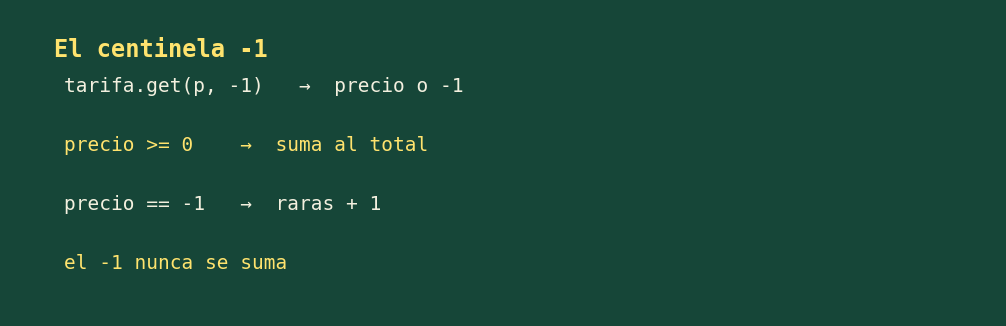

In [ ]:
dibujar_pizarra(
    'El centinela -1',
    [('tarifa.get(p, -1)   →  precio o -1', TIZA), ('precio >= 0    →  suma al total', TIZA_AMARILLA), ('precio == -1   →  raras + 1', TIZA), ('el -1 nunca se suma', TIZA_AMARILLA)],
    ancho=10, alto=3.2,
)

In [ ]:
tarifa = {"camara": 8, "pastillas": 12, "cadena": 15}
ticket = ["cadena", "camara", "luces", "camara"]
total = 0
raras = 0
for p in ticket:
    precio = tarifa.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        raras = raras + 1
print("total:", total)
print("raras:", raras)

total: 31
raras: 1


In [ ]:
filas_b4 = [{'vuelta': '1', 'p': 'cadena', 'precio': '15', 'total': '15', 'raras': '0'}, {'vuelta': '2', 'p': 'camara', 'precio': '8', 'total': '23', 'raras': '0'}, {'vuelta': '3', 'p': 'luces', 'precio': '-1', 'total': '23', 'raras': '1'}, {'vuelta': '4', 'p': 'camara', 'precio': '8', 'total': '31', 'raras': '1'}]
traza_pasos(filas_b4, ['vuelta', 'p', 'precio', 'total', 'raras'])

vuelta,p,precio,total,raras
1,cadena,15,15,0
2,camara,8,23,0
3,luces,-1,23,1
4,camara,8,31,1


**Paso a paso.** `tarifa.get(p, -1)` devuelve el precio o el centinela -1 si la pieza no está en la tarifa. Solo se suma cuando `precio >= 0`: las luces dan -1 y engordan `raras` en lugar del total. Se imprime `total: 31` y `raras: 1`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=tarifa%20%3D%20%7B%22camara%22%3A%208%2C%20%22pastillas%22%3A%2012%2C%20%22cadena%22%3A%2015%7D%0Aticket%20%3D%20%5B%22cadena%22%2C%20%22camara%22%2C%20%22luces%22%2C%20%22camara%22%5D%0Atotal%20%3D%200%0Araras%20%3D%200%0Afor%20p%20in%20ticket%3A%0A%20%20%20%20precio%20%3D%20tarifa.get%28p%2C%20-1%29%0A%20%20%20%20if%20precio%20%3E%3D%200%3A%0A%20%20%20%20%20%20%20%20total%20%3D%20total%20%2B%20precio%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20raras%20%3D%20raras%20%2B%201%0Aprint%28%22total%3A%22%2C%20total%29%0Aprint%28%22raras%3A%22%2C%20raras%29%0A&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Tabla de variables: columnas correctas según la lista dada (0,5) · valores al final de cada vuelta correctos, incluida la vuelta del break cuando lo hay (1,0) · sin filas ni columnas inventadas (0,5) | 2,0 |
| Salida exacta: contenido correcto (0,5) · orden y formato exactos — corchetes, comillas, orden de líneas (0,5) | 1,0 |

#### Errores frecuentes

- Arrastrar `precio` de una vuelta a otra en lugar de reasignarlo: la nota del enunciado lo advierte.
- Sumar el -1 de las luces al total.
- Contar las luces como pieza de la tarifa.

## C1 · Primera bici que pasa del límite (4 puntos)

### Enunciado exacto

Marina mide el desgaste de las pastillas de freno de cada bici que entra, en el orden de la cola, y quiere saber en qué posición está la primera que supera el límite de seguridad (la primera posición es la 0).

Escribe la función `primera_revision(mediciones, limite)` que reciba una lista de números y un número `limite`, y devuelva la posición de la primera medición estrictamente mayor que `limite`, o `-1` si ninguna lo supera.

Ejemplos:

```text
- primera_revision([3, 8, 12, 6], 10) → 2
- primera_revision([3, 8], 10) → -1
```

### Pizarra

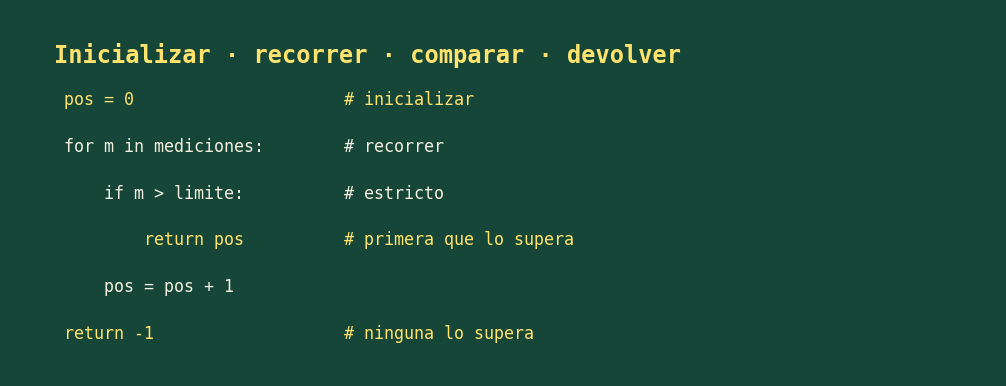

In [ ]:
dibujar_pizarra(
    'Inicializar · recorrer · comparar · devolver',
    [('pos = 0                     # inicializar', TIZA_AMARILLA), ('for m in mediciones:        # recorrer', TIZA), ('    if m > limite:          # estricto', TIZA), ('        return pos          # primera que lo supera', TIZA_AMARILLA), ('    pos = pos + 1', TIZA), ('return -1                   # ninguna lo supera', TIZA_AMARILLA)],
    ancho=10, alto=3.8,
)

In [ ]:
def primera_revision(mediciones, limite):
    pos = 0                    # posición actual dentro de la lista
    for m in mediciones:
        if m > limite:
            return pos         # primera que supera el límite
        pos = pos + 1
    return -1                  # ninguna lo supera

print(primera_revision([3, 8, 12, 6], 10))
print(primera_revision([3, 8], 10))

2
-1


In [ ]:
ejemplos = [('primera_revision([3, 8, 12, 6], 10)', '2'), ('primera_revision([3, 8], 10)', '-1'), ('primera_revision([], 5)', '-1'), ('primera_revision([11, 2], 10)', '0'), ('primera_revision([5, 5], 5)', '-1')]
primera_revision.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(primera_revision, "primera_revision")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
print(f"Verificado primera_revision: {resumen.attempted} pruebas, 0 fallos")

Trying:
    primera_revision([3, 8, 12, 6], 10)
Expecting:
    2
ok
Trying:
    primera_revision([3, 8], 10)
Expecting:
    -1
ok
Trying:
    primera_revision([], 5)
Expecting:
    -1
ok
Trying:
    primera_revision([11, 2], 10)
Expecting:
    0
ok
Trying:
    primera_revision([5, 5], 5)
Expecting:
    -1
ok
1 items passed all tests:
   5 tests in primera_revision
5 tests in 1 items.
5 passed and 0 failed.
Test passed.
Verificado primera_revision: 5 pruebas, 0 fallos


**Paso a paso.** `pos` guarda la posición que se está mirando. El `for` recorre la lista; en cuanto una medición supera el límite (`>` estricto) se devuelve `pos`, que es la primera. Si el recorrido termina sin superarlo, se devuelve -1.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20primera_revision%28mediciones%2C%20limite%29%3A%0A%20%20%20%20pos%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20posici%C3%B3n%20actual%20dentro%20de%20la%20lista%0A%20%20%20%20for%20m%20in%20mediciones%3A%0A%20%20%20%20%20%20%20%20if%20m%20%3E%20limite%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20pos%20%20%20%20%20%20%20%20%20%23%20primera%20que%20supera%20el%20l%C3%ADmite%0A%20%20%20%20%20%20%20%20pos%20%3D%20pos%20%2B%201%0A%20%20%20%20return%20-1%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20ninguna%20lo%20supera%0A%0Aprint%28primera_revision%28%5B3%2C%208%2C%2012%2C%206%5D%2C%2010%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Firma según contrato: `primera_revision(mediciones, limite)`. | 0,5 |
| Recorrido de la lista con índice propio. | 1,0 |
| Comparación estricta y `return` de la posición en la primera que supera el límite. | 1,0 |
| `return -1` tras el bucle. | 1,0 |
| Devuelve el valor, no lo imprime. | 0,5 |

#### Errores frecuentes

- Devolver la medición encontrada en lugar de su posición.
- Usar `>=` en lugar de `>`: una medición igual al límite no lo supera.
- Poner un `return` en la primera vuelta o usar `print` en lugar de `return`.

## C2 · Palabras cortas de una nota de taller (4 puntos)

### Enunciado exacto

Las clientas dejan notas en el mostrador con lo que le pasa a su bici. Marina quiere contar cuántas palabras cortas tiene una nota, entendiendo por corta una palabra con una longitud estrictamente menor que `maximo`.

Escribe la función `contar_cortas(texto, maximo)` que reciba una cadena (puede tener espacios extra al principio y al final) y un entero `maximo`, y devuelva cuántas palabras tienen una longitud estrictamente menor que `maximo`.

Ejemplos:

```text
- contar_cortas("rueda pinchada hoy", 7) → 2
- contar_cortas("", 5) → 0
```

### Pizarra

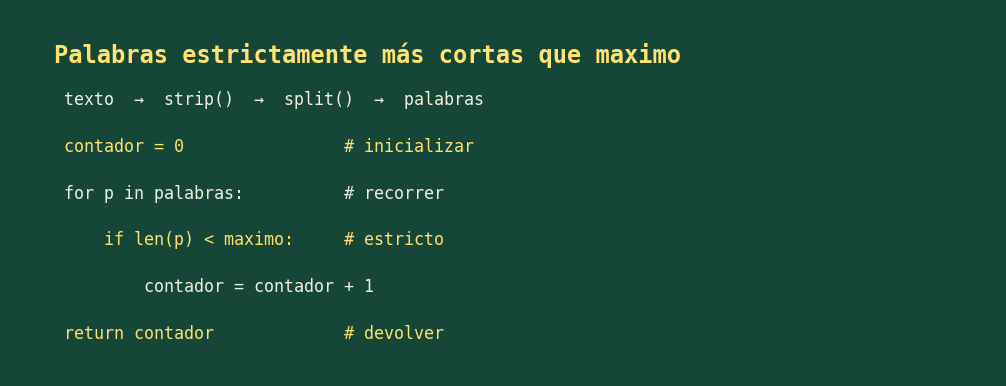

In [ ]:
dibujar_pizarra(
    'Palabras estrictamente más cortas que maximo',
    [('texto  →  strip()  →  split()  →  palabras', TIZA), ('contador = 0                # inicializar', TIZA_AMARILLA), ('for p in palabras:          # recorrer', TIZA), ('    if len(p) < maximo:     # estricto', TIZA_AMARILLA), ('        contador = contador + 1', TIZA), ('return contador             # devolver', TIZA_AMARILLA)],
    ancho=10, alto=3.8,
)

In [ ]:
def contar_cortas(texto, maximo):
    limpio = texto.strip()     # quitamos espacios de los extremos
    palabras = limpio.split()  # lista de palabras; cadena vacía -> lista vacía
    contador = 0
    for p in palabras:
        if len(p) < maximo:
            contador = contador + 1
    return contador

print(contar_cortas("rueda pinchada hoy", 7))
print(contar_cortas("", 5))

2
0


In [ ]:
ejemplos = [('contar_cortas("rueda pinchada hoy", 7)', '2'), ('contar_cortas("", 5)', '0'), ('contar_cortas("  eje   roto  ", 4)', '1'), ('contar_cortas("abc", 3)', '0'), ('contar_cortas("ok", 10)', '1')]
contar_cortas.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(contar_cortas, "contar_cortas")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
print(f"Verificado contar_cortas: {resumen.attempted} pruebas, 0 fallos")

Trying:
    contar_cortas("rueda pinchada hoy", 7)
Expecting:
    2
ok
Trying:
    contar_cortas("", 5)
Expecting:
    0
ok
Trying:
    contar_cortas("  eje   roto  ", 4)
Expecting:
    1
ok
Trying:
    contar_cortas("abc", 3)
Expecting:
    0
ok
Trying:
    contar_cortas("ok", 10)
Expecting:
    1
ok
1 items passed all tests:
   5 tests in contar_cortas
5 tests in 1 items.
5 passed and 0 failed.
Test passed.
Verificado contar_cortas: 5 pruebas, 0 fallos


**Paso a paso.** `strip()` quita los espacios de los extremos y `split()` parte el texto en palabras (con una cadena vacía produce una lista vacía). El contador solo sube cuando `len(p) < maximo`, con el menor estricto: una palabra de exactamente `maximo` letras no cuenta.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20contar_cortas%28texto%2C%20maximo%29%3A%0A%20%20%20%20limpio%20%3D%20texto.strip%28%29%20%20%20%20%20%23%20quitamos%20espacios%20de%20los%20extremos%0A%20%20%20%20palabras%20%3D%20limpio.split%28%29%20%20%23%20lista%20de%20palabras%3B%20cadena%20vac%C3%ADa%20-%3E%20lista%20vac%C3%ADa%0A%20%20%20%20contador%20%3D%200%0A%20%20%20%20for%20p%20in%20palabras%3A%0A%20%20%20%20%20%20%20%20if%20len%28p%29%20%3C%20maximo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20return%20contador%0A%0Aprint%28contar_cortas%28%22rueda%20pinchada%20hoy%22%2C%207%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Firma según contrato: `contar_cortas(texto, maximo)`. | 0,5 |
| `strip` + `split` correctos. | 1,0 |
| Condición `len(p) < maximo` estricta. | 1,0 |
| Contador y `return` correctos. | 1,0 |
| Devuelve el valor, no lo imprime. | 0,5 |

#### Errores frecuentes

- Escribir `len(p) <= maximo`: la condición es estricta y las palabras de exactamente `maximo` letras no cuentan.
- Contar caracteres en lugar de palabras.
- Usar `print` en lugar de `return`.

## C3 · Reposición con techo del almacén (4 puntos)

### Enunciado exacto

Marina repone el almacén: a cada estantería le suma `extra` unidades, pero el proveedor no permite pasar del `tope` en ninguna. Tiene las unidades actuales en una lista, en el orden de las estanterías.

Escribe la función `subir_stock(unidades, extra, tope)` que reciba una lista de unidades y dos números, `extra` y `tope`, y devuelva una lista nueva con cada cantidad aumentada en `extra`. Ninguna cantidad puede quedar por encima de `tope` y la lista original no debe cambiar.

Ejemplos:

```text
- subir_stock([2, 9], 5, 10) → [7, 10]
- subir_stock([4], 0, 10) → [4]
- subir_stock([], 3, 10) → []
```

### Pizarra

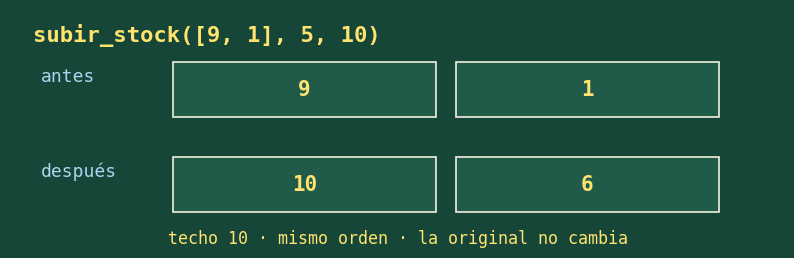

In [ ]:
dibujar_listas_doble([9, 1], [10, 6], 'subir_stock([9, 1], 5, 10)', nota='techo 10 · mismo orden · la original no cambia')

In [ ]:
def subir_stock(unidades, extra, tope):
    nuevas = []
    for u in unidades:
        nuevo = u + extra
        if nuevo > tope:
            nuevo = tope
        nuevas.append(nuevo)
    return nuevas

print(subir_stock([2, 9], 5, 10))
print(subir_stock([4], 0, 10))
print(subir_stock([], 3, 10))

[7, 10]
[4]
[]


In [ ]:
ejemplos = [('subir_stock([2, 9], 5, 10)', '[7, 10]'), ('subir_stock([4], 0, 10)', '[4]'), ('subir_stock([], 3, 10)', '[]'), ('subir_stock([9, 1], 5, 10)', '[10, 6]'), ('subir_stock([0], 3, 2)', '[2]')]
subir_stock.__doc__ = "".join(
    ">>> " + llamada + "\n" + esperado + "\n"
    for llamada, esperado in ejemplos
)
pruebas = doctest.DocTestFinder().find(subir_stock, "subir_stock")
runner = doctest.DocTestRunner(verbose=True)
for prueba in pruebas:
    runner.run(prueba)
resumen = runner.summarize()
assert resumen.failed == 0
original = [9, 1]
subidas = subir_stock(original, 5, 10)
assert subidas == [10, 6]
assert original == [9, 1]
assert subidas is not original
print("lista nueva correcta: la original no se ha tocado")
print(f"Verificado subir_stock: {resumen.attempted} pruebas, 0 fallos")

Trying:
    subir_stock([2, 9], 5, 10)
Expecting:
    [7, 10]
ok
Trying:
    subir_stock([4], 0, 10)
Expecting:
    [4]
ok
Trying:
    subir_stock([], 3, 10)
Expecting:
    []
ok
Trying:
    subir_stock([9, 1], 5, 10)
Expecting:
    [10, 6]
ok
Trying:
    subir_stock([0], 3, 2)
Expecting:
    [2]
ok
1 items passed all tests:
   5 tests in subir_stock
5 tests in 1 items.
5 passed and 0 failed.
Test passed.
lista nueva correcta: la original no se ha tocado
Verificado subir_stock: 5 pruebas, 0 fallos


**Paso a paso.** Se crea una lista nueva `nuevas` y se recorre `unidades` en orden. A cada cantidad se le suma `extra`; si se pasara del `tope` se queda en el tope. Cada resultado se añade a `nuevas` y la lista original queda intacta.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20subir_stock%28unidades%2C%20extra%2C%20tope%29%3A%0A%20%20%20%20nuevas%20%3D%20%5B%5D%0A%20%20%20%20for%20u%20in%20unidades%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20u%20%2B%20extra%0A%20%20%20%20%20%20%20%20if%20nuevo%20%3E%20tope%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20nuevo%20%3D%20tope%0A%20%20%20%20%20%20%20%20nuevas.append%28nuevo%29%0A%20%20%20%20return%20nuevas%0A%0Aprint%28subir_stock%28%5B2%2C%209%5D%2C%205%2C%2010%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|---|
| Inicializa una lista nueva vacía. | 1 |
| Recorre todas las unidades en orden. | 1 |
| Suma el extra y aplica el techo. | 1 |
| Añade cada resultado y devuelve la lista nueva sin cambiar la original. | 1 |

Se aceptan algoritmos equivalentes.

#### Errores frecuentes

- Modificar `unidades` en el sitio: hay que crear una lista nueva.
- Olvidar el techo y devolver cantidades por encima de él.
- Perder el orden de las estanterías al construir la lista nueva.

# Resumen final

| Ejercicio | Respuesta oficial | Puntos |
|---|---|---:|
| A1-A6 | c) 3 · c) 3 3 · b) 45 4 · b) None 6 · b) media · c) 12 | 1 c/u |
| B1 | tabla de 3 filas; `marca: 12 · vueltas: 3` | 3 |
| B2 | tabla de 3 filas; `casilla: 2` | 3 |
| B3 | tabla de 5 filas; `['4', '9'] · resto: 3` | 3 |
| B4 | tabla de 4 filas; `total: 31 · raras: 1` | 3 |
| C1 | `primera_revision`: 2, -1, -1, 0, -1 | 4 |
| C2 | `contar_cortas`: 2, 0, 1, 0, 1 | 4 |
| C3 | `subir_stock`: [7, 10], [4], [], [10, 6], [2] | 4 |
| **Total** | **A: 6 · B: 12 · C: 12** | **30** |

## Dudas frecuentes

**¿Por qué A1 imprime 3 y no 4?**  
La condición `bicis > 3` se comprueba antes de cada vuelta; cuando `bicis` vale 3 el bucle ya no entra.

**¿Por qué A6 imprime 12 y no 10?**  
El contador sube de tres en tres (3, 6, 9, 12) y el `if` solo pide llegar a 10 o más: al saltar de 9 a 12 ya se cumple y el `break` sale con 12.

**¿Por qué `hallada` empieza en -1 en B2?**  
Es el centinela de «aún no se ha encontrado nada»; la nota del enunciado lo aclara.

**¿Cuenta la vuelta en la que salta el `break`?**  
Sí: la rúbrica pide los valores al final de cada vuelta, incluida la vuelta del break.

**¿Tiene que ser exacta la salida?**  
Sí: en cada ejercicio de la parte B, 0,5 puntos corresponden al orden y al formato exactos (corchetes, comillas, orden de las líneas).

**¿Puedo usar `while` en C1 o prescindir de `append` en C3?**  
Sí: se aceptan algoritmos equivalentes que cumplan el contrato con lo visto en clase.

**¿Puedo modificar la lista original en C3?**  
No: hay que devolver una lista nueva y dejar la original intacta.